# Evolution Simulation Niger
Niger serves as an extreme region that is hot and arid desert.

In [201]:
import utils.param_loader as param_loader
import numpy as np

from utils.evolution import run_evolution_simulation
from utils.evolution_plotting import (
    plot_grouped_trait_dynamics,
    plot_delta13C_trajectory_clean,
    plot_3d_evolution_trajectory,
    plot_pareto_front,
    # plot_evolution_trajectory,
    plot_evolution_direction,
    plot_evolution_overview,
    plot_evolution_summary,
    plot_3d_evolution_interactive,
    plot_hybrid_evolution_view,
    _sanitize_history,
    # plot_fraction_fitness_map,
)

In [202]:
# param_loader.store_api_parameters(set_name='niger', longitude = 11.0, latitude = 22.0, date='20230615')

In [203]:
params = param_loader.load_parameters(environmental_params='niger')

In [204]:
from concurrent.futures import ProcessPoolExecutor
import pickle

try:
    pickle.dumps(tuple(sorted(params.items())))
    print("✅ frozen_params is serializable")
except Exception as e:
    print("❌ not serializable:", e)

✅ frozen_params is serializable


## Evolvable Traits

In [205]:
evolving_traits = [
    "g_bs",  # bundle sheath conductance
    "g_m",  # mesophyll conductance
    "f_pepc",  # enzyme budget fraction for PEPC
    "f_rubisco_mes",  # enzyme budget fraction for mesophyll Rubisco
    "f_rubisco_bs",  # enzyme budget fraction for BS Rubisco
    "k_c",
    "k_o",
    "k_p",
]

bounds = [
    [0.0001, 0.1],  # g_bs
    [1, 6],  # g_m
    [0.0, 0.6],  # f_pepc (up to 60% for strong C4)
    [0.0, 0.9],  # f_rubisco_mes
    [0.0, 0.9],  # f_rubisco_bs
    [1000.0, 100000.0],  # k_c
    [7500.0, 27500000.0],  # k_o
    [1000.0, 70000000.0],  # k_p
]

initial_c3_like = {
    "g_bs": 0.0015,
    "g_m": 5.0,
    "f_pepc": 0.3,  # almost no PEPC
    "f_rubisco_mes": 0.05,  # mostly mesophyll Rubisco
    "f_rubisco_bs": 0.65,  # small BS Rubisco activity
    "k_c": 6500.0,
    "k_o": 2_000_000.0,
    "k_p": 500_0.0,
}

In [206]:
# evolving_traits = [
#     "g_bs",
#     "g_m",
#     "v_pmax",
#     "v_cmax_mes",
#     "v_cmax_bs",
#     "k_c",
#     "k_o",
#     "k_p",
# ]

# bounds = [
#     [0.0001, 0.1],  # g_bs
#     [1, 6],  # g_m
#     [0.1, 220],  # v_pmax
#     [0.1, 220],  # v_cmax_mes
#     [0.1, 220],  # v_cmax_bs
#     [1000.0, 100000.0],  # k_c
#     [7500.0, 27500000.0],  # k_o
#     [1000.0, 70000000.0],  # k_p
# ]

In [207]:
# initial_c3_like = {
#     "g_bs": 0.0015,  # very low BS leakiness typical of C3 (tight barrier)
#     "g_m": 5.0,  # high mesophyll conductance
#     "f_pepc": 0.0,  # almost no PEPC
#     "f_rubisco_mes": .990,  # mostly mesophyll Rubisco
#     "f_rubisco_bs": 0.01,  # small BS Rubisco activity
#     "k_c": 6500.0,  # Rubisco affinity typical of C3 (moderate)
#     "k_o": 2000000.0,  # oxygen affinity typical of C3
#     "k_p": 5000.0,  # PEPC affinity low (non-specialized enzyme)
# }

## Evolution Simulation

In [208]:
# initial_c3_like = {
#     "g_bs": 2.5e-6,
#     "g_m": 0.12,
#     "v_pmax": 0.2,
#     "v_cmax_mes": 80.0,
#     "v_cmax_bs": 1.0,
#     "k_c": 0.065,
#     "k_o": 20.0,
#     "k_p": 0.005,
# }

In [209]:
number_of_generations = 100
population_size = 100

In [210]:
loaded_history = run_evolution_simulation(
    evolving_traits=evolving_traits,
    bounds=bounds,
    base_params=params,
    n_generations=number_of_generations,
    pop_size=population_size,
    sigma0=1,  # Adjust as needed; higher = more exploration
    beta= 2.5,  # Adjust as needed; higher = more exploitation
    initial_traits=initial_c3_like,  # you can set the initial start of the simulations
    verbose=False,
)




Hybrid evolution: 100%|██████████| 100/100 [01:29<00:00,  1.12it/s, mean_fit=12.83, best_fit=12.87, σ=0.05]


In [211]:
# Select elite individuals (e.g., top per generation or last generation)
elite_indices = list(
    range(
        0,
        len(loaded_history["traits"]),
        len(loaded_history["traits"]) // number_of_generations,
    )
)
elite_traits = [loaded_history["traits"][i] for i in elite_indices]
elite_fitness = [loaded_history["fitness"][i] for i in elite_indices]

# # 3D evolution trajectory
# plot_3d_evolution_trajectory(
#     trait_history=elite_traits,
#     fitness_history=elite_fitness,
#     save_path="plots/evolution/niger/3d_evolution_trajectory.png",
#     cmap_name="plasma",  # or "viridis", "inferno", etc.
# )

/home/foko.kuate/Final_yvonne /bachelor_project-main/photosynthesis_model/utils/evolution_plotting.py:416: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



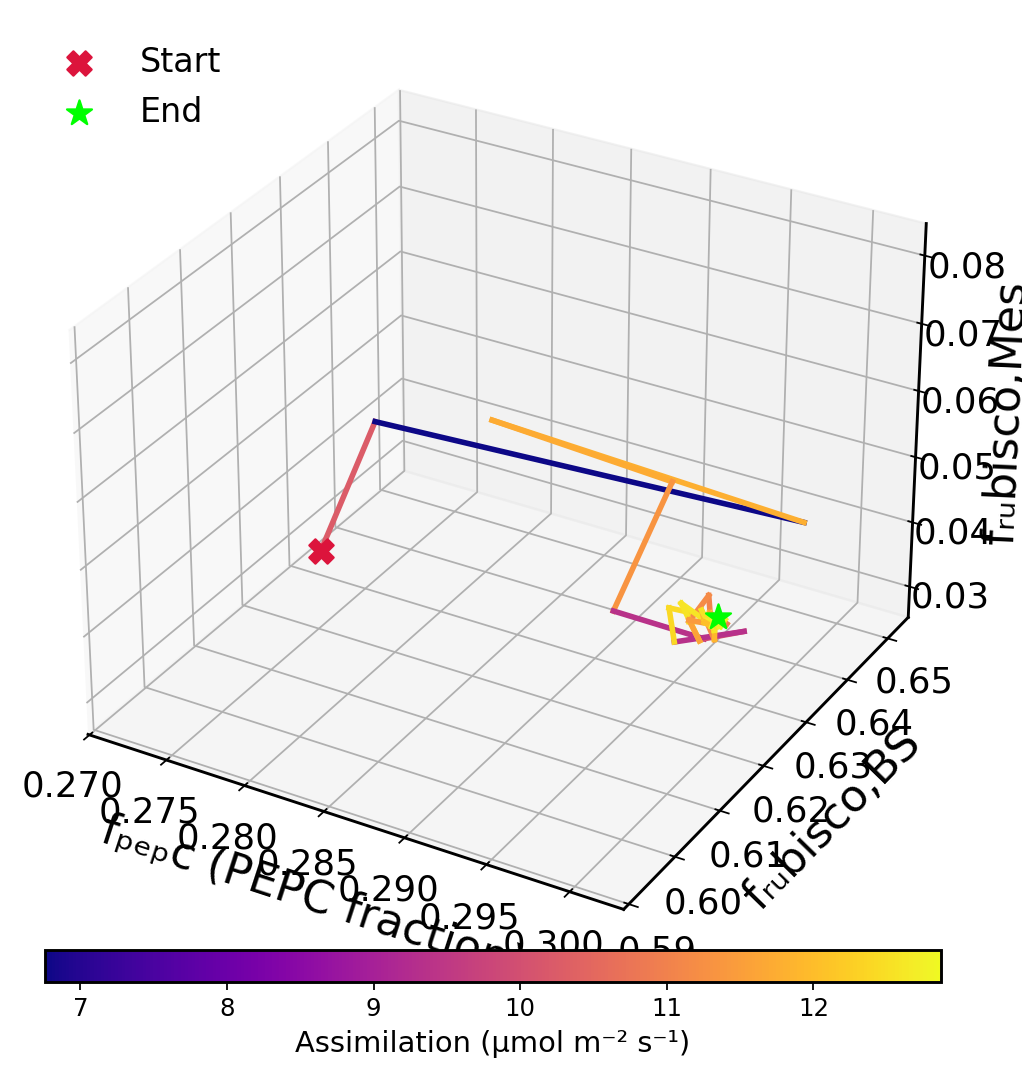

/home/foko.kuate/Final_yvonne /bachelor_project-main/photosynthesis_model/utils/evolution_plotting.py:520: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



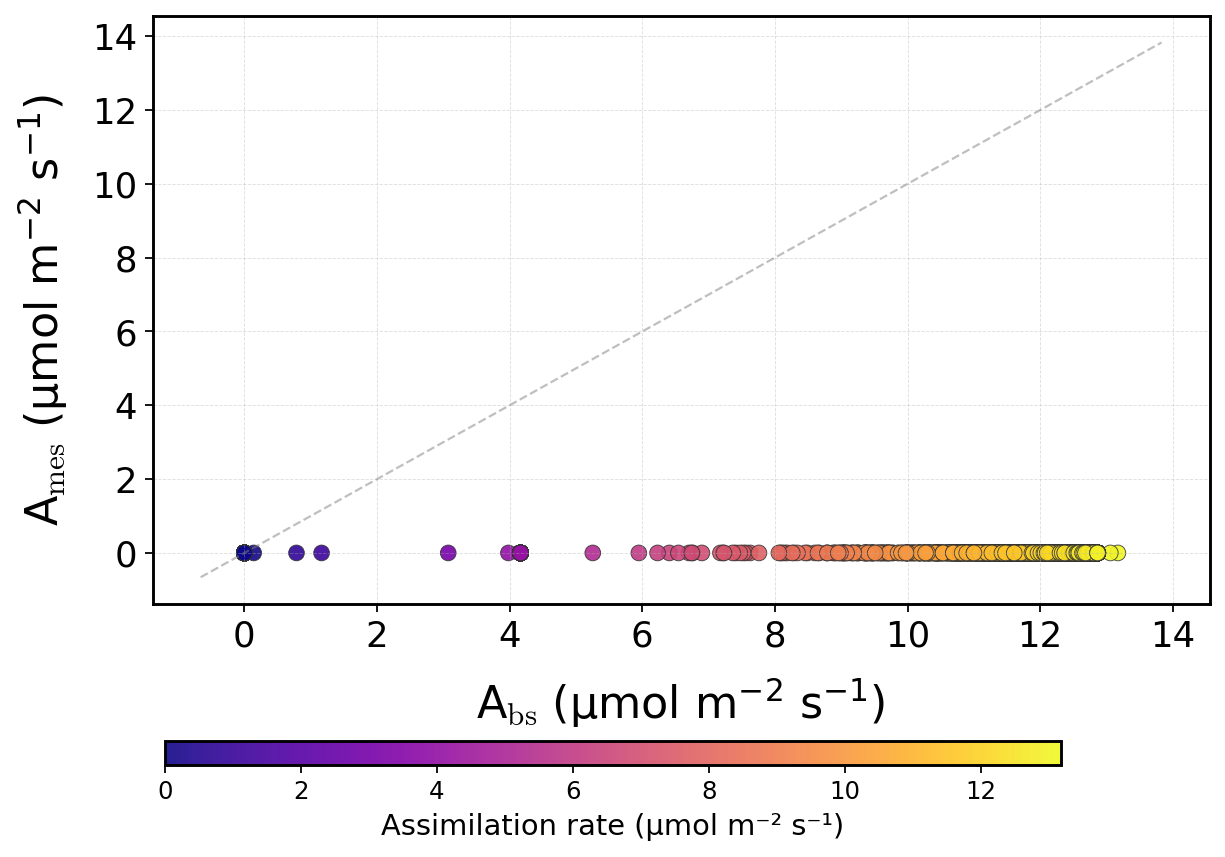

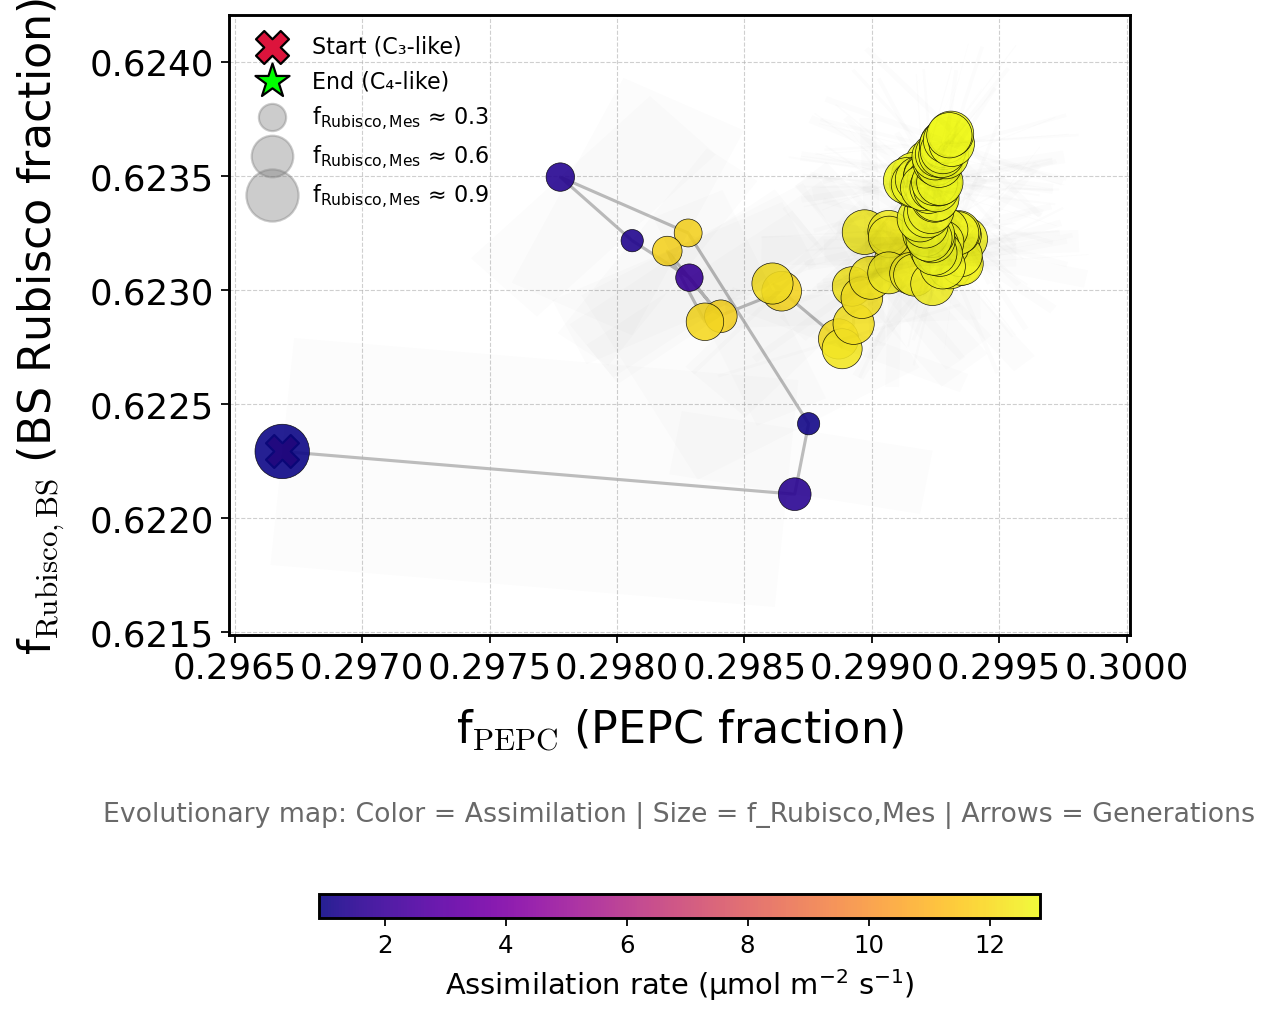

⚠️ No valid (finite) values found for v_cmax_mes vs v_cmax_bs.


In [212]:
loaded_history = _sanitize_history(loaded_history)

plot_3d_evolution_trajectory(elite_traits, elite_fitness)
plot_pareto_front(loaded_history["fitness_bs"], loaded_history["fitness_mes"])
plot_evolution_overview(loaded_history)
plot_evolution_direction(loaded_history, "v_cmax_mes", "v_cmax_bs")

/home/foko.kuate/Final_yvonne /bachelor_project-main/photosynthesis_model/utils/evolution_plotting.py:891: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



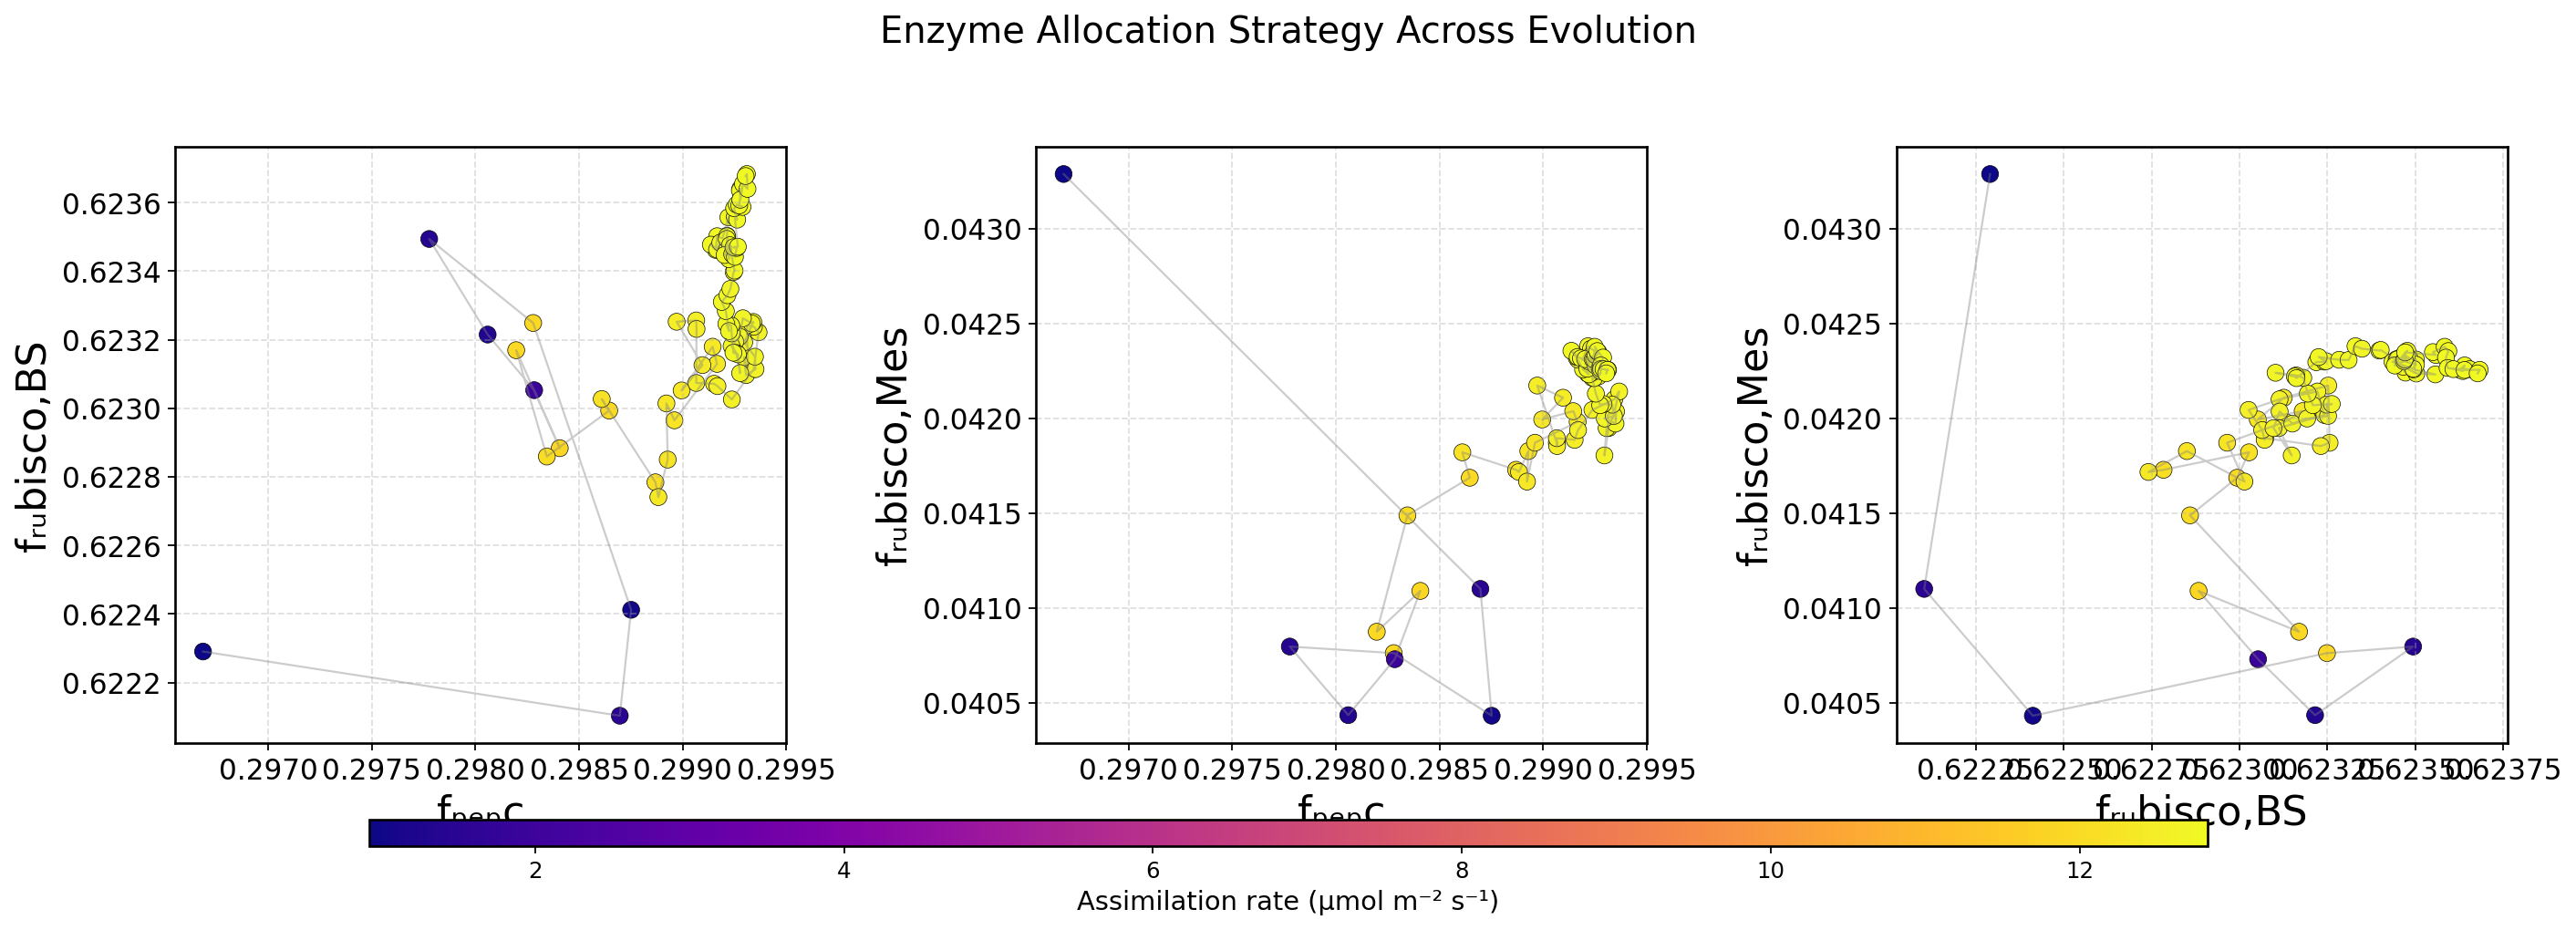

/home/foko.kuate/Final_yvonne /bachelor_project-main/photosynthesis_model/utils/evolution_plotting.py:1060: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



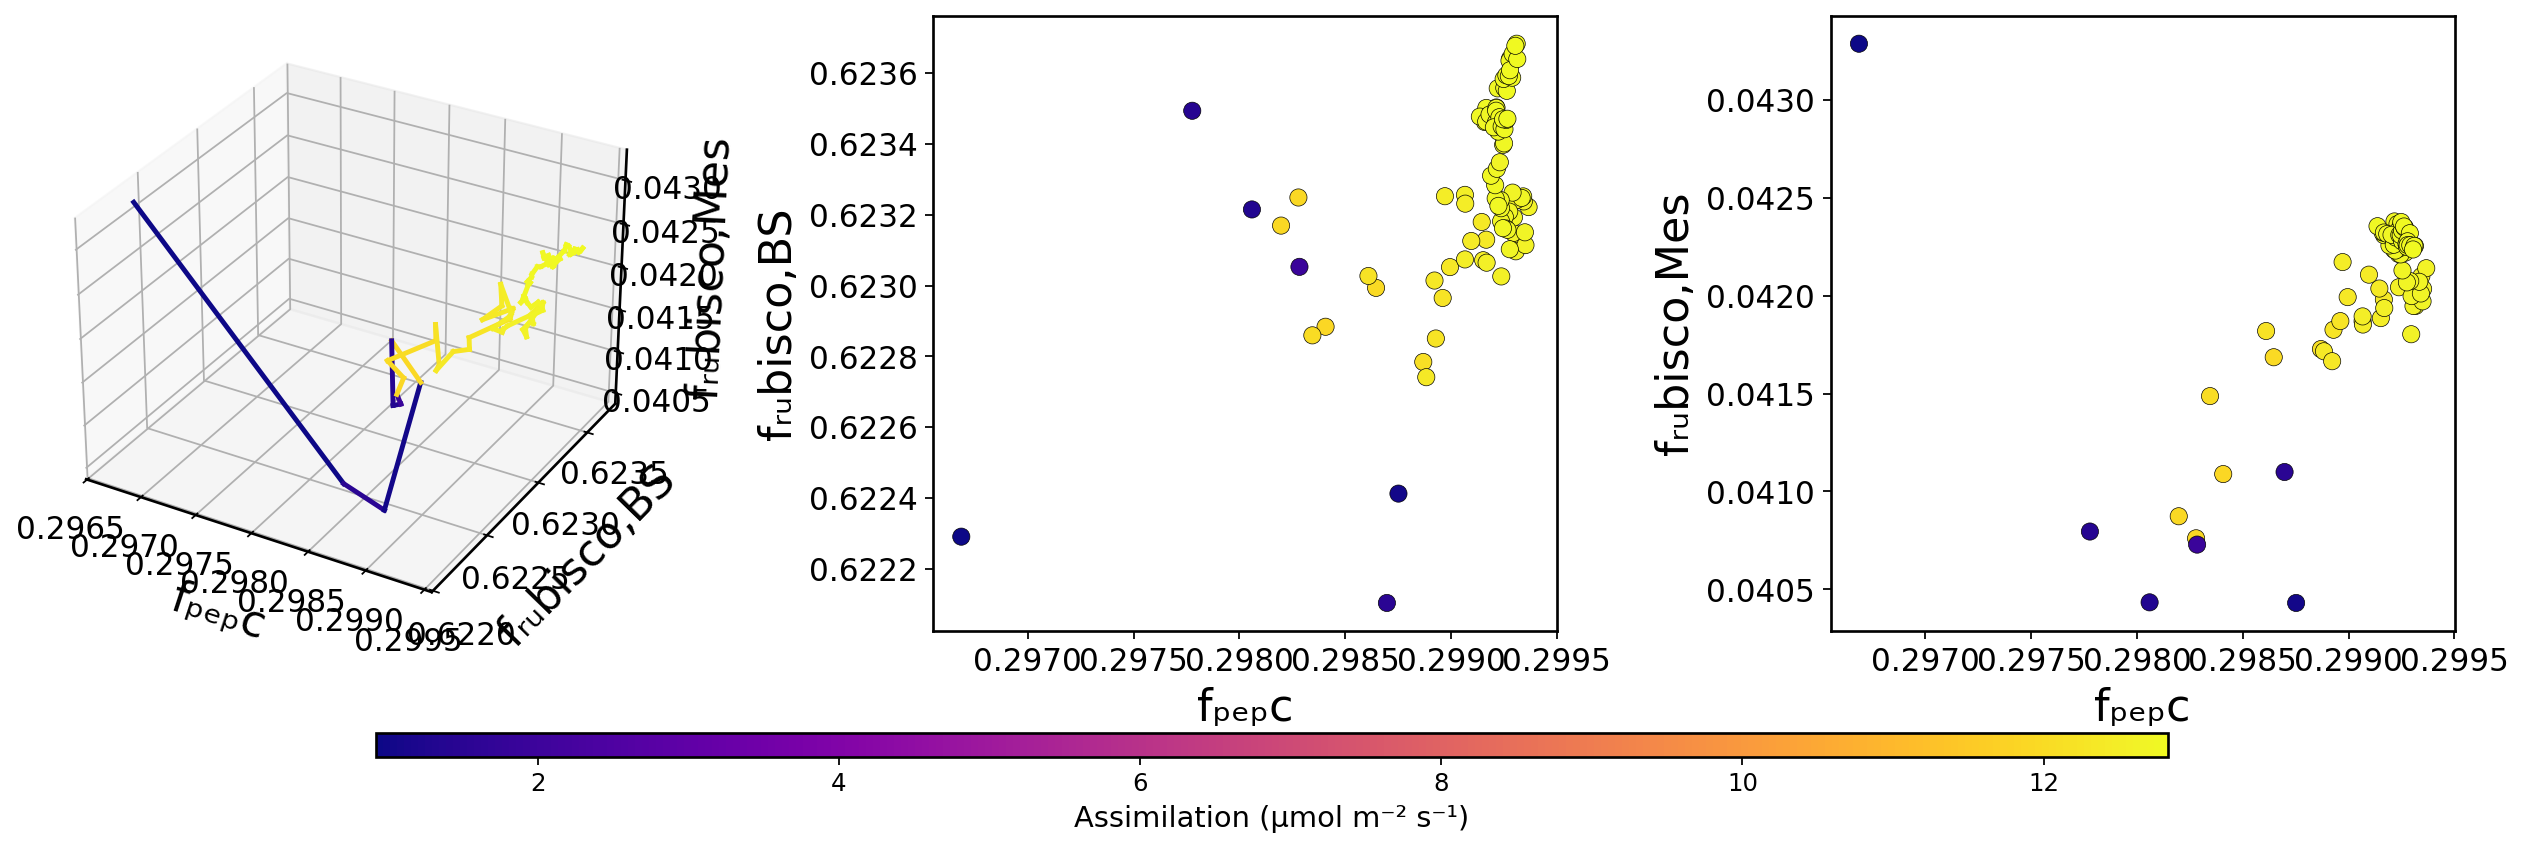

In [213]:
loaded_history = _sanitize_history(loaded_history)

plot_evolution_summary(loaded_history, save_path="plots/evolution/summary.png")
plot_3d_evolution_interactive(loaded_history, save_html="plots/evolution/evo_3d.html")
plot_hybrid_evolution_view(loaded_history, save_path="plots/evolution/hybrid_view.png")

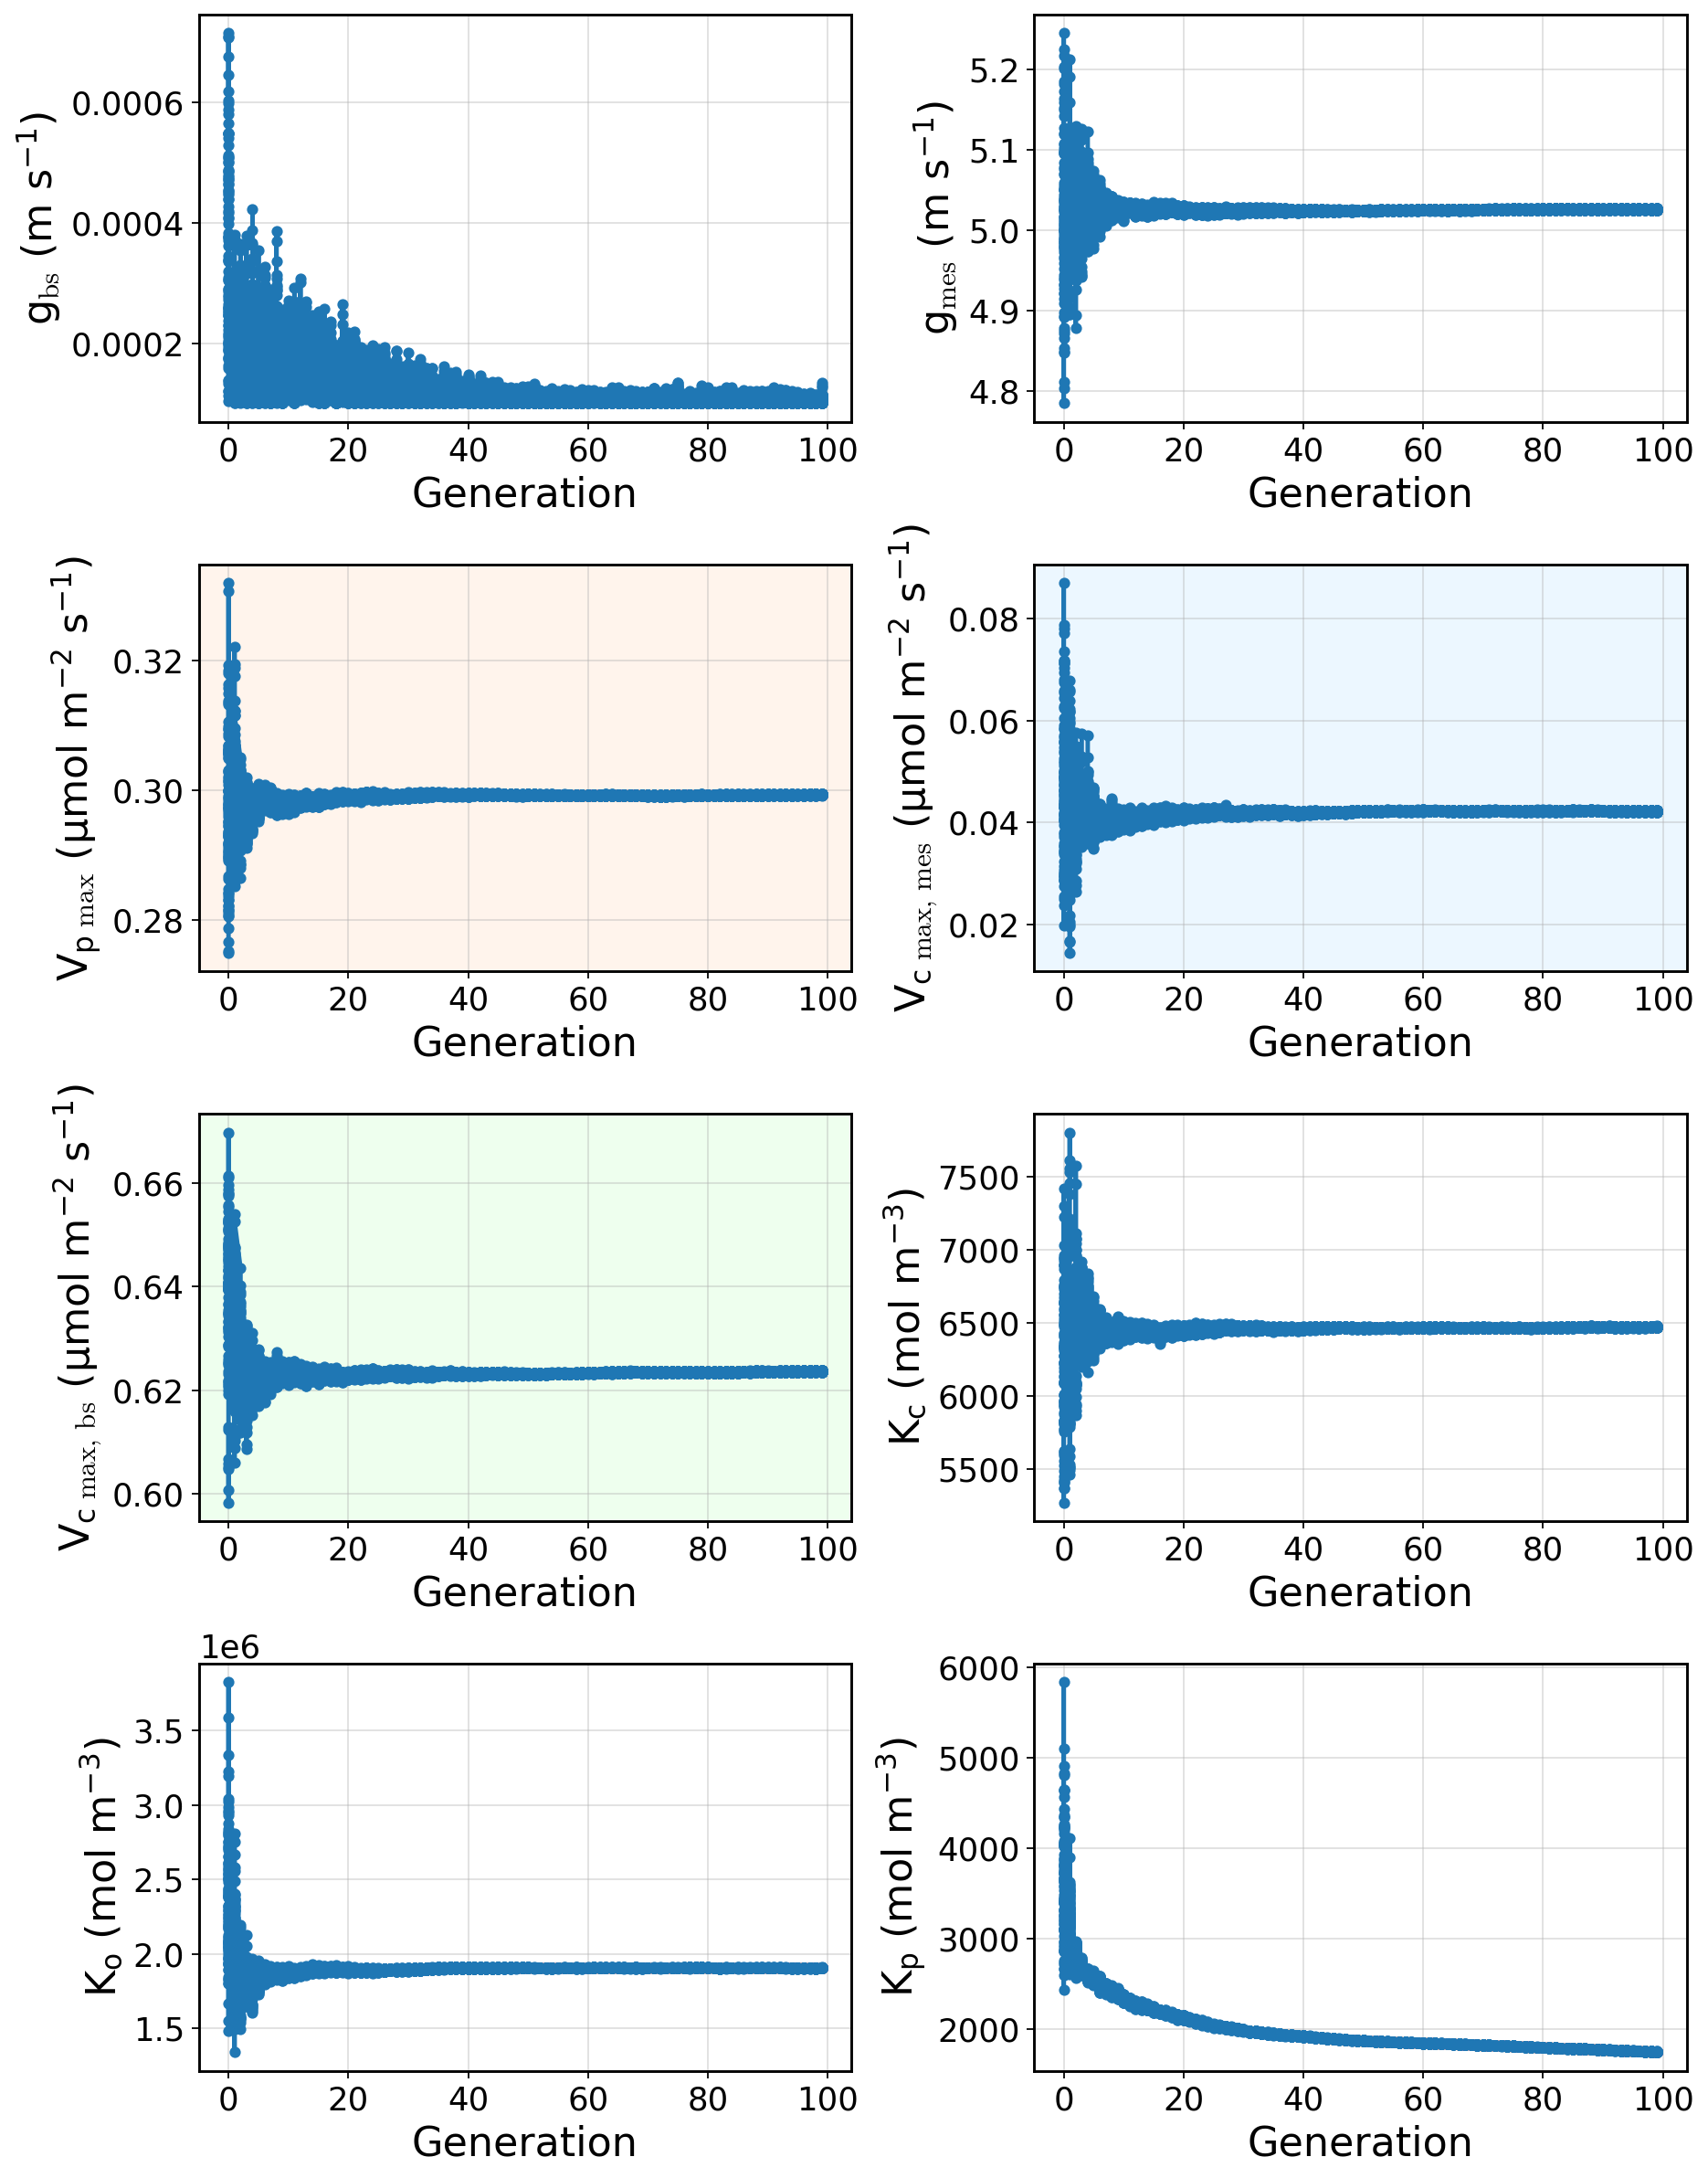

In [214]:
from utils.evolution_plotting import (
    plot_grouped_trait_dynamics, 
    plot_delta13C_trajectory_clean,
    plot_3d_evolution_trajectory,
    plot_pareto_front
)

trait_names = [
    "$g_{\\text{bs}}$ (m s$^{-1}$)",
    "$g_{\\text{mes}}$ (m s$^{-1}$)",
    "$V_{p~\\max}$ ($\\mu$mol m$^{-2}$ s$^{-1}$)",
    "$V_{c~\\text{max, mes}}$ ($\\mu$mol m$^{-2}$ s$^{-1}$)",
    "$V_{c~\\text{max, bs}}$ ($\\mu$mol m$^{-2}$ s$^{-1}$)",
    "$K_c$ (mol m$^{-3}$)",
    "$K_o$ (mol m$^{-3}$)",
    "$K_p$ (mol m$^{-3}$)"
]

# Plot trait dynamics
plot_grouped_trait_dynamics(loaded_history["traits"], 
                            evolving_traits, 
                            trait_names, 
                            loaded_history["delta13C_generations"],
                            save_path="plots/evolution/niger/single_traits_niger.png")

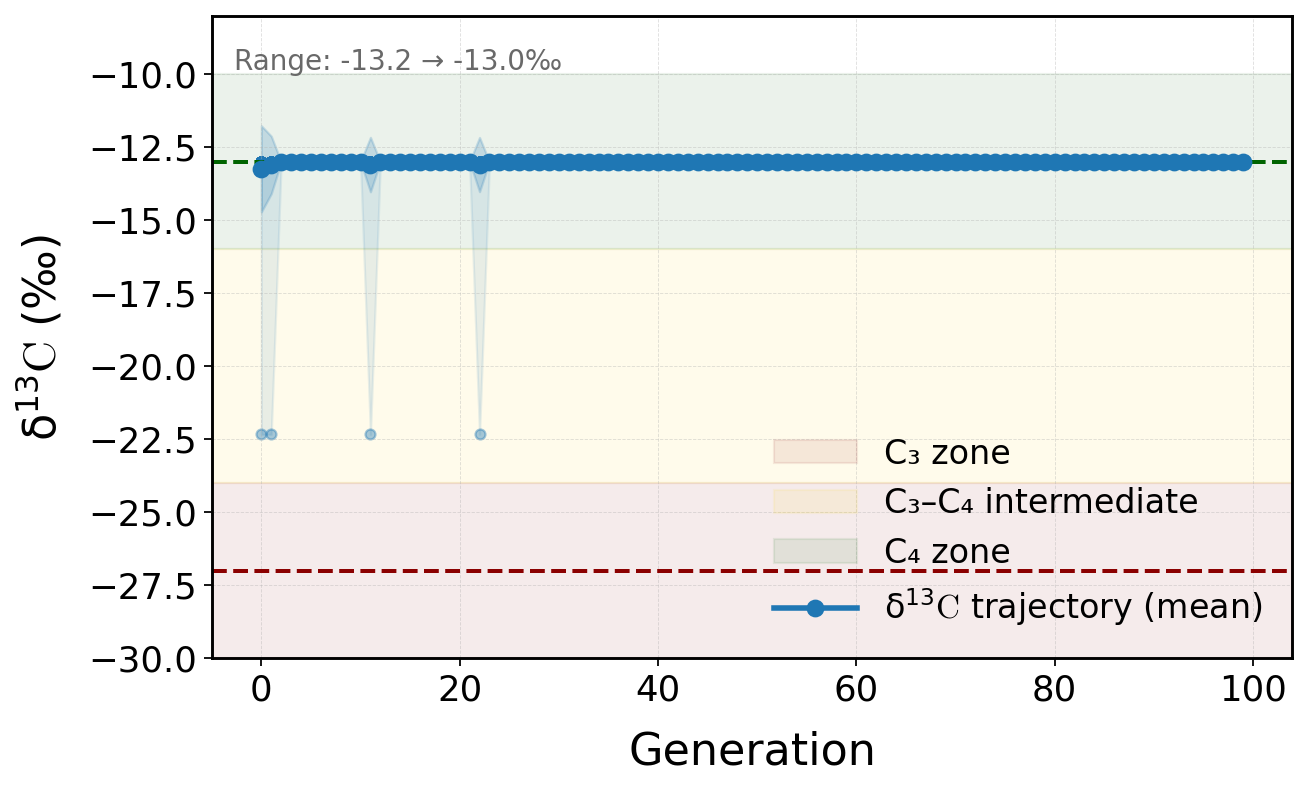

In [215]:
# Plot δ13C trajectory if valid data exists
if any(np.isfinite(d) for d in loaded_history["delta13C"]):
    plot_delta13C_trajectory_clean(
        loaded_history["delta13C"], 
        loaded_history["delta13C_generations"],
        save_path="plots/evolution/niger/delta13C_trajectory_niger.png",
        smooth_sigma= 0.001,
        annotate= True
    )
else:
    print("[INFO] No valid δ13C data to plot.")

In [216]:
loaded_history["delta13C"]

[-13.000000002732154,
 nan,
 -13.000000002571513,
 -13.000000002344109,
 -13.000000002384185,
 nan,
 nan,
 nan,
 -13.000000002280256,
 -13.000000002458828,
 -13.000000002185793,
 nan,
 -13.000000002268903,
 -13.000000002328315,
 nan,
 nan,
 nan,
 -13.000000007031858,
 -13.000000006722377,
 nan,
 nan,
 nan,
 nan,
 nan,
 nan,
 -13.000000006722486,
 nan,
 -13.000000002283183,
 nan,
 -22.333333333333336,
 nan,
 nan,
 -13.000000002583622,
 nan,
 -13.000000004706969,
 nan,
 nan,
 nan,
 nan,
 nan,
 -13.000000006724834,
 nan,
 -13.00000000672473,
 nan,
 -13.000000006722807,
 nan,
 nan,
 nan,
 nan,
 -13.00000000242835,
 -13.000000006723894,
 nan,
 nan,
 nan,
 -13.000000002330545,
 nan,
 nan,
 -13.000000006722377,
 -13.000000002382444,
 -13.000000002125686,
 nan,
 nan,
 nan,
 nan,
 nan,
 -13.000000002712715,
 -13.000000006724914,
 nan,
 nan,
 nan,
 nan,
 nan,
 -13.000000002483498,
 nan,
 -13.000000035614141,
 nan,
 nan,
 -13.00000000672483,
 nan,
 -13.000000009107309,
 -13.00000000299016,
 nan,


/home/foko.kuate/Final_yvonne /bachelor_project-main/photosynthesis_model/utils/evolution_plotting.py:416: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



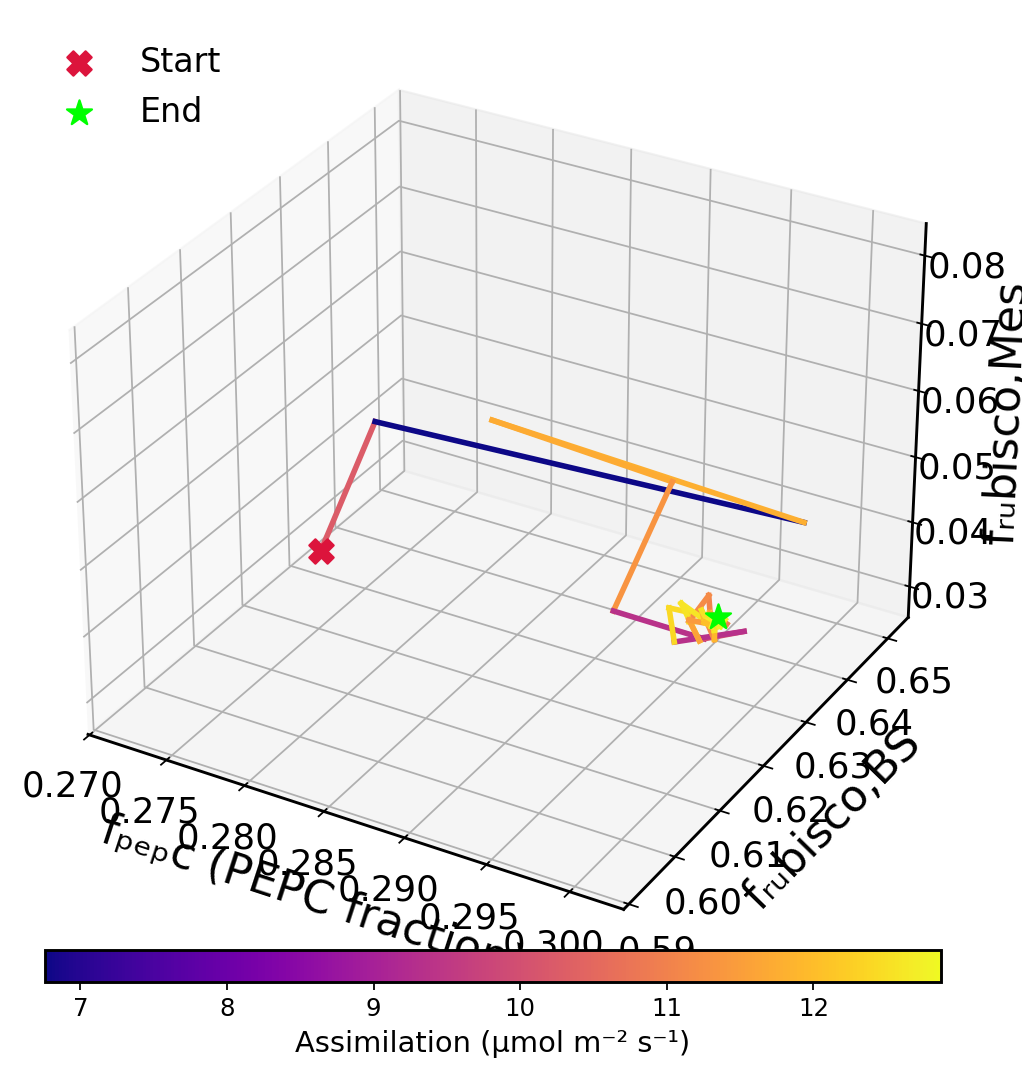

In [217]:
# Select elite individuals (e.g., top per generation or last generation)
elite_indices = list(
    range(
        0,
        len(loaded_history["traits"]),
        len(loaded_history["traits"]) // number_of_generations,
    )
)
elite_traits = [loaded_history["traits"][i] for i in elite_indices]
elite_fitness = [loaded_history["fitness"][i] for i in elite_indices]

# 3D evolution trajectory
plot_3d_evolution_trajectory(
    trait_history=elite_traits,
    fitness_history=elite_fitness,
    save_path="plots/evolution/niger/3d_evolution_trajectory.png",
    cmap_name="plasma",  # or "viridis", "inferno", etc.
)

/home/foko.kuate/Final_yvonne /bachelor_project-main/photosynthesis_model/utils/evolution_plotting.py:520: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



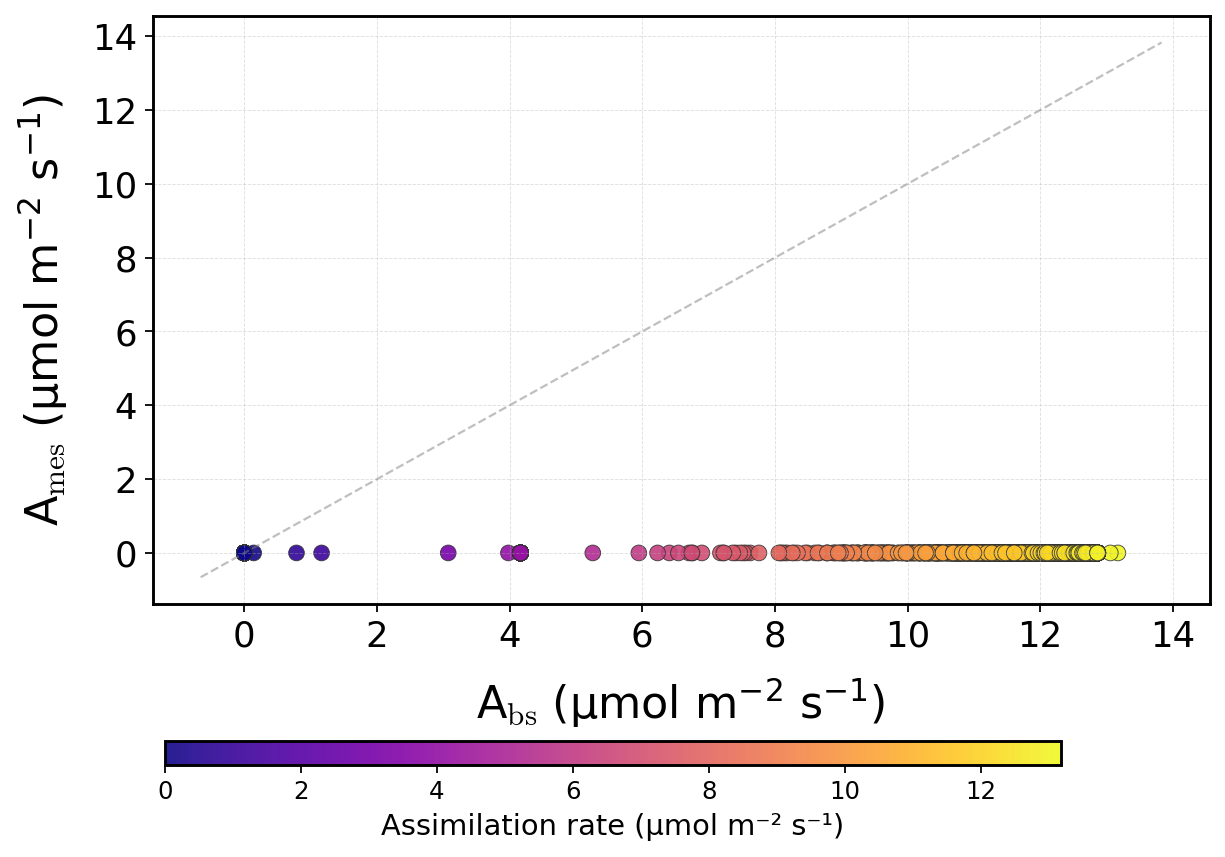

In [218]:
def safe_extract(lst, idx):
    """Safely get element at index, else np.nan."""
    return lst[idx] if idx < len(lst) else np.nan

# Pareto front plot
plot_pareto_front(
    fitness_bs=[
        safe_extract(loaded_history["fitness_bs"], i)
        for i in range(0, len(loaded_history["fitness_bs"]))
    ],
    fitness_mes=[
        safe_extract(loaded_history["fitness_mes"], i)
        for i in range(0, len(loaded_history["fitness_mes"]))
    ],
    save_path="plots/evolution/niger/pareto_front_niger.png"
)

In [219]:
# plot_evolution_trajectory(
#     loaded_history,
#     trait_x="v_cmax_mes",
#     trait_y="v_pmax",
#     save_path="plots/evolution/niger/evolution_trajectory_vcmax_vpmax.png",
# )

⚠️ No valid (finite) values found for v_cmax_mes vs v_cmax_bs.


/home/foko.kuate/Final_yvonne /bachelor_project-main/photosynthesis_model/utils/evolution_plotting.py:891: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



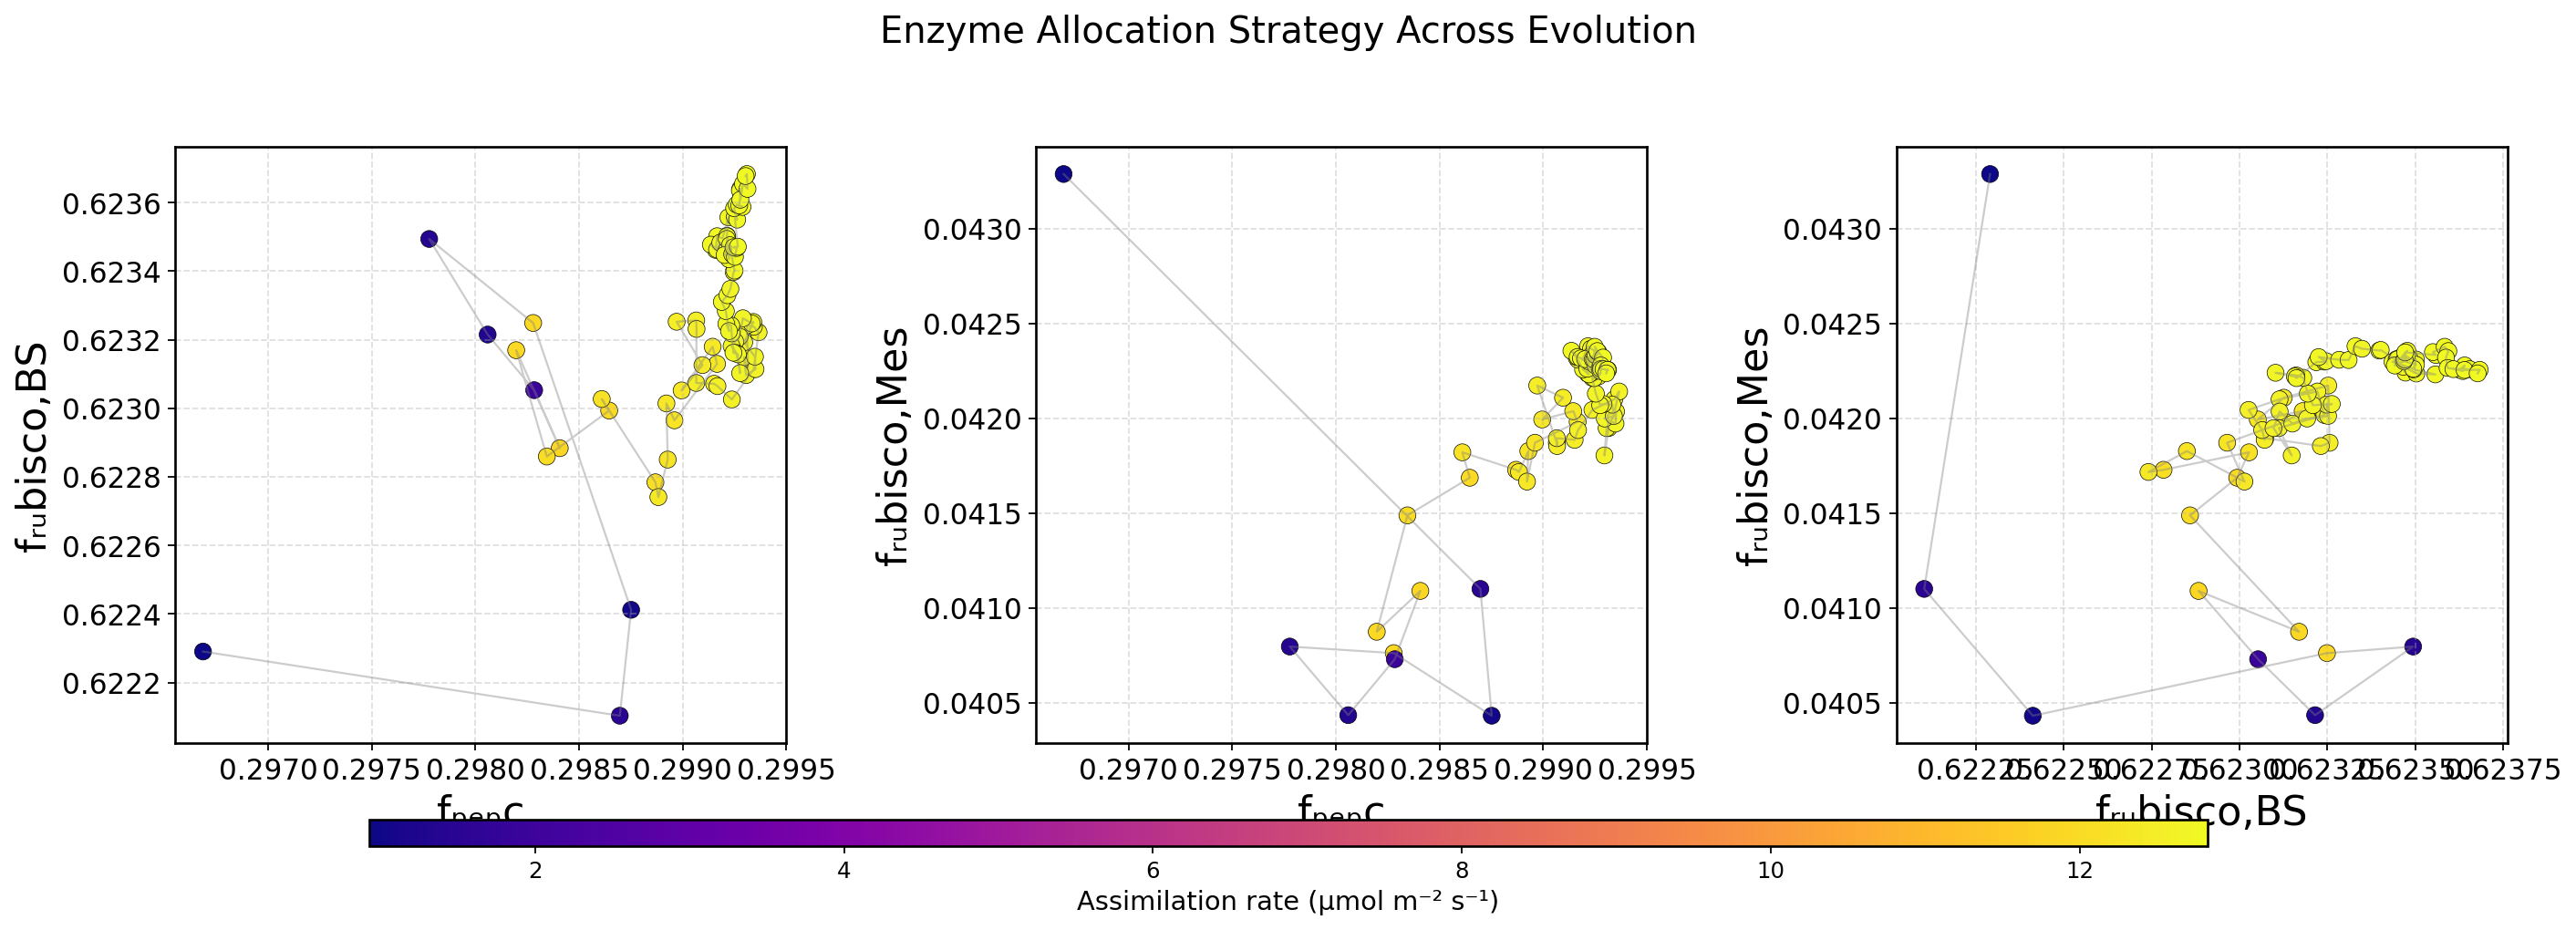

/home/foko.kuate/Final_yvonne /bachelor_project-main/photosynthesis_model/utils/evolution_plotting.py:1060: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



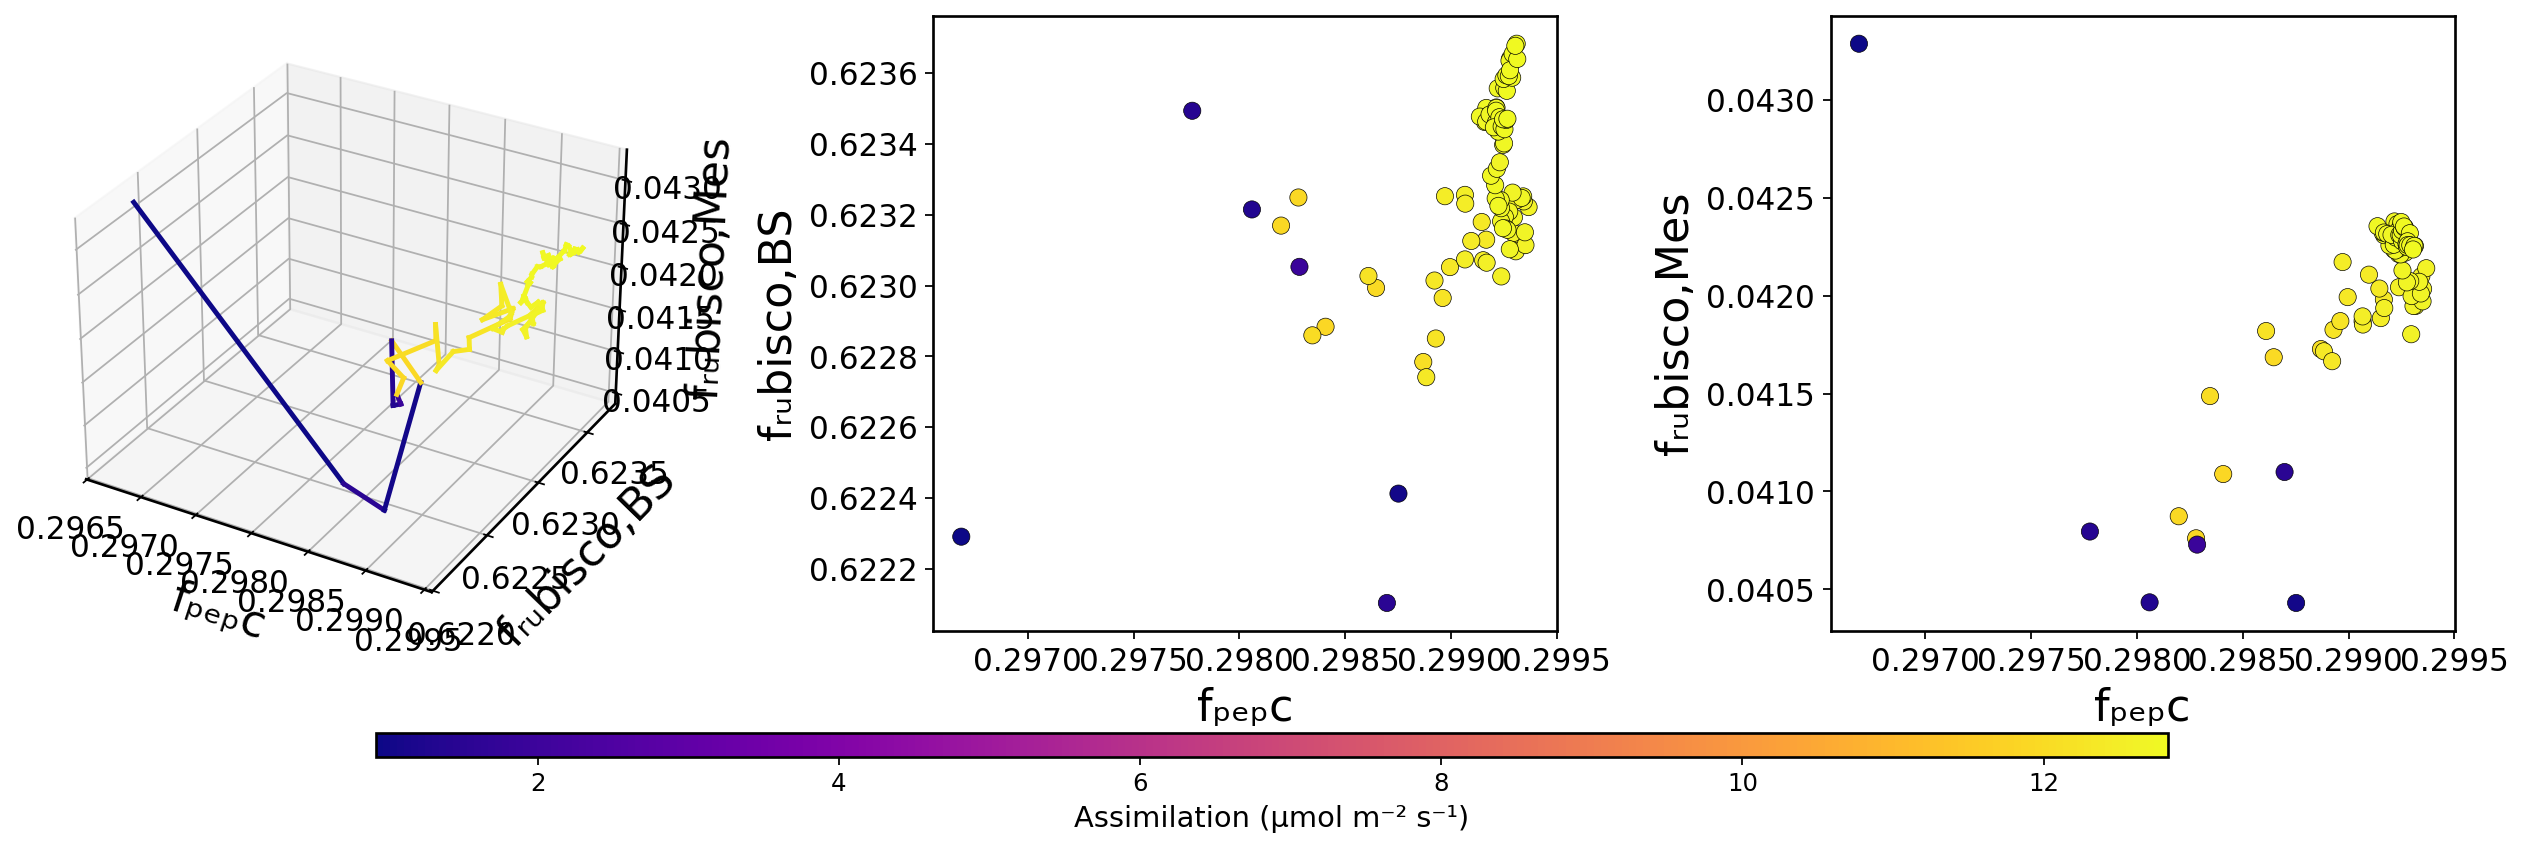

In [220]:
plot_evolution_direction(
    history=loaded_history,
    trait_x="v_cmax_mes",
    trait_y="v_cmax_bs",
    save_path="plots/evolution/niger/evolution_direction_vmax.png",
    cmap_name="plasma",
)

plot_evolution_summary(loaded_history)
plot_hybrid_evolution_view(loaded_history)

In [221]:
for key in ["v_cmax_mes", "v_cmax_bs"]:
    values = [t.get(key, None) for t in loaded_history.get("mean_traits_per_gen", [])]
    print(f"{key}: {np.isfinite(values).sum()} finite values out of {len(values)}")
    print(values[:10])

for key in ["v_cmax_mes", "v_cmax_bs"]:
    values = np.array(
        [t.get(key, np.nan) for t in loaded_history.get("mean_vmax_per_gen", [])],
        dtype=float,
    )
    finite_count = np.isfinite(values).sum()
    print(f"{key}: {finite_count} finite values out of {len(values)}")
    print("First 10 values:", values[:10])
    print("-" * 60)

v_cmax_mes: 0 finite values out of 100
[nan, nan, nan, nan, nan, nan, nan, nan, nan, nan]
v_cmax_bs: 0 finite values out of 100
[nan, nan, nan, nan, nan, nan, nan, nan, nan, nan]
v_cmax_mes: 0 finite values out of 0
First 10 values: []
------------------------------------------------------------
v_cmax_bs: 0 finite values out of 0
First 10 values: []
------------------------------------------------------------


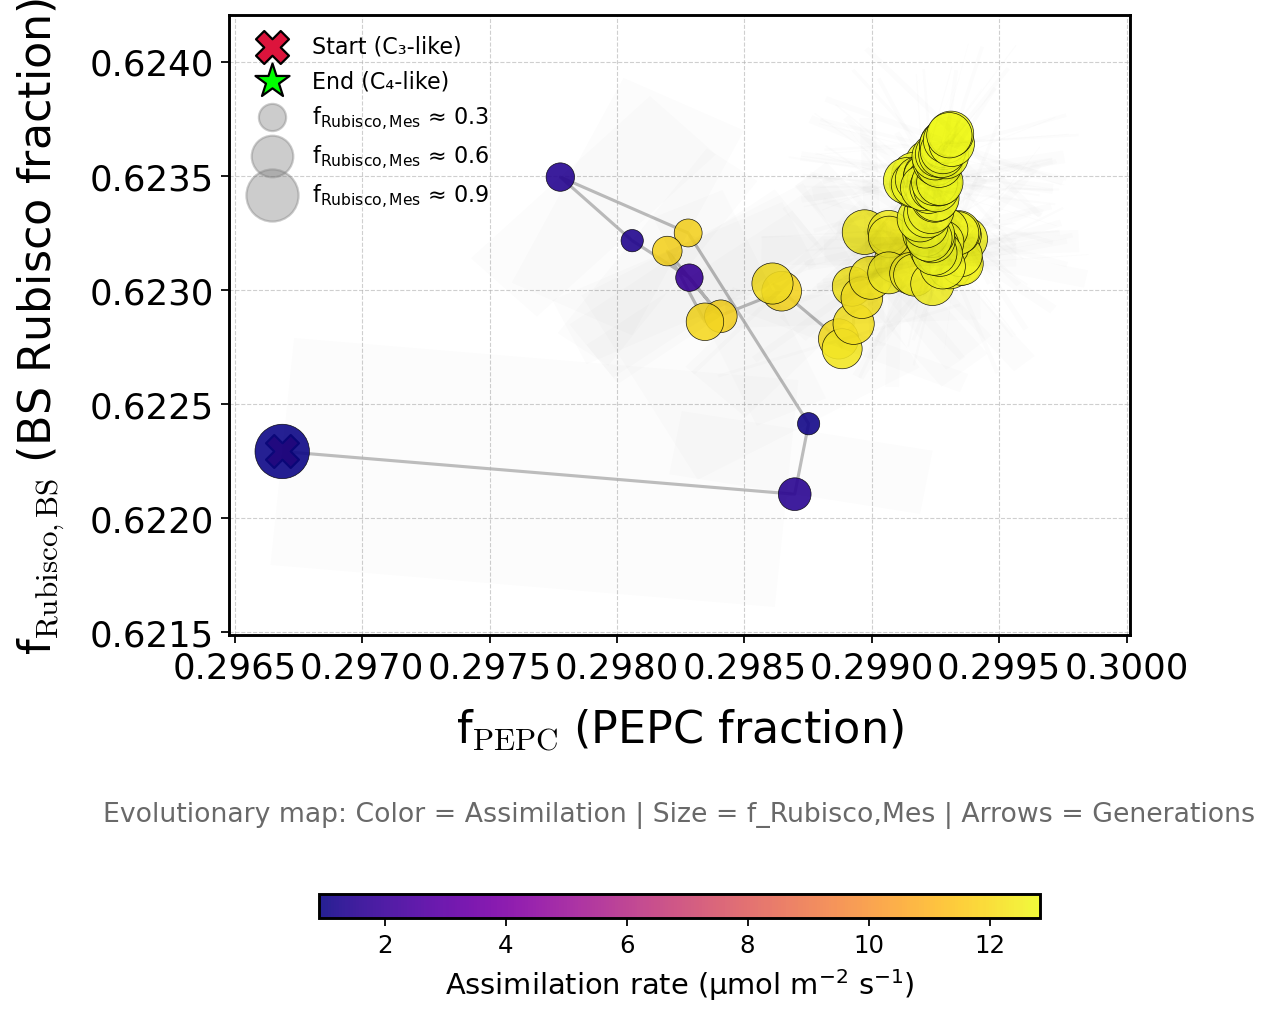

In [222]:
plot_evolution_overview(
    loaded_history,
    save_path="plots/evolution/niger/evolution_overview_niger.png",
)

/home/foko.kuate/Final_yvonne /bachelor_project-main/photosynthesis_model/utils/evolution_plotting.py:891: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



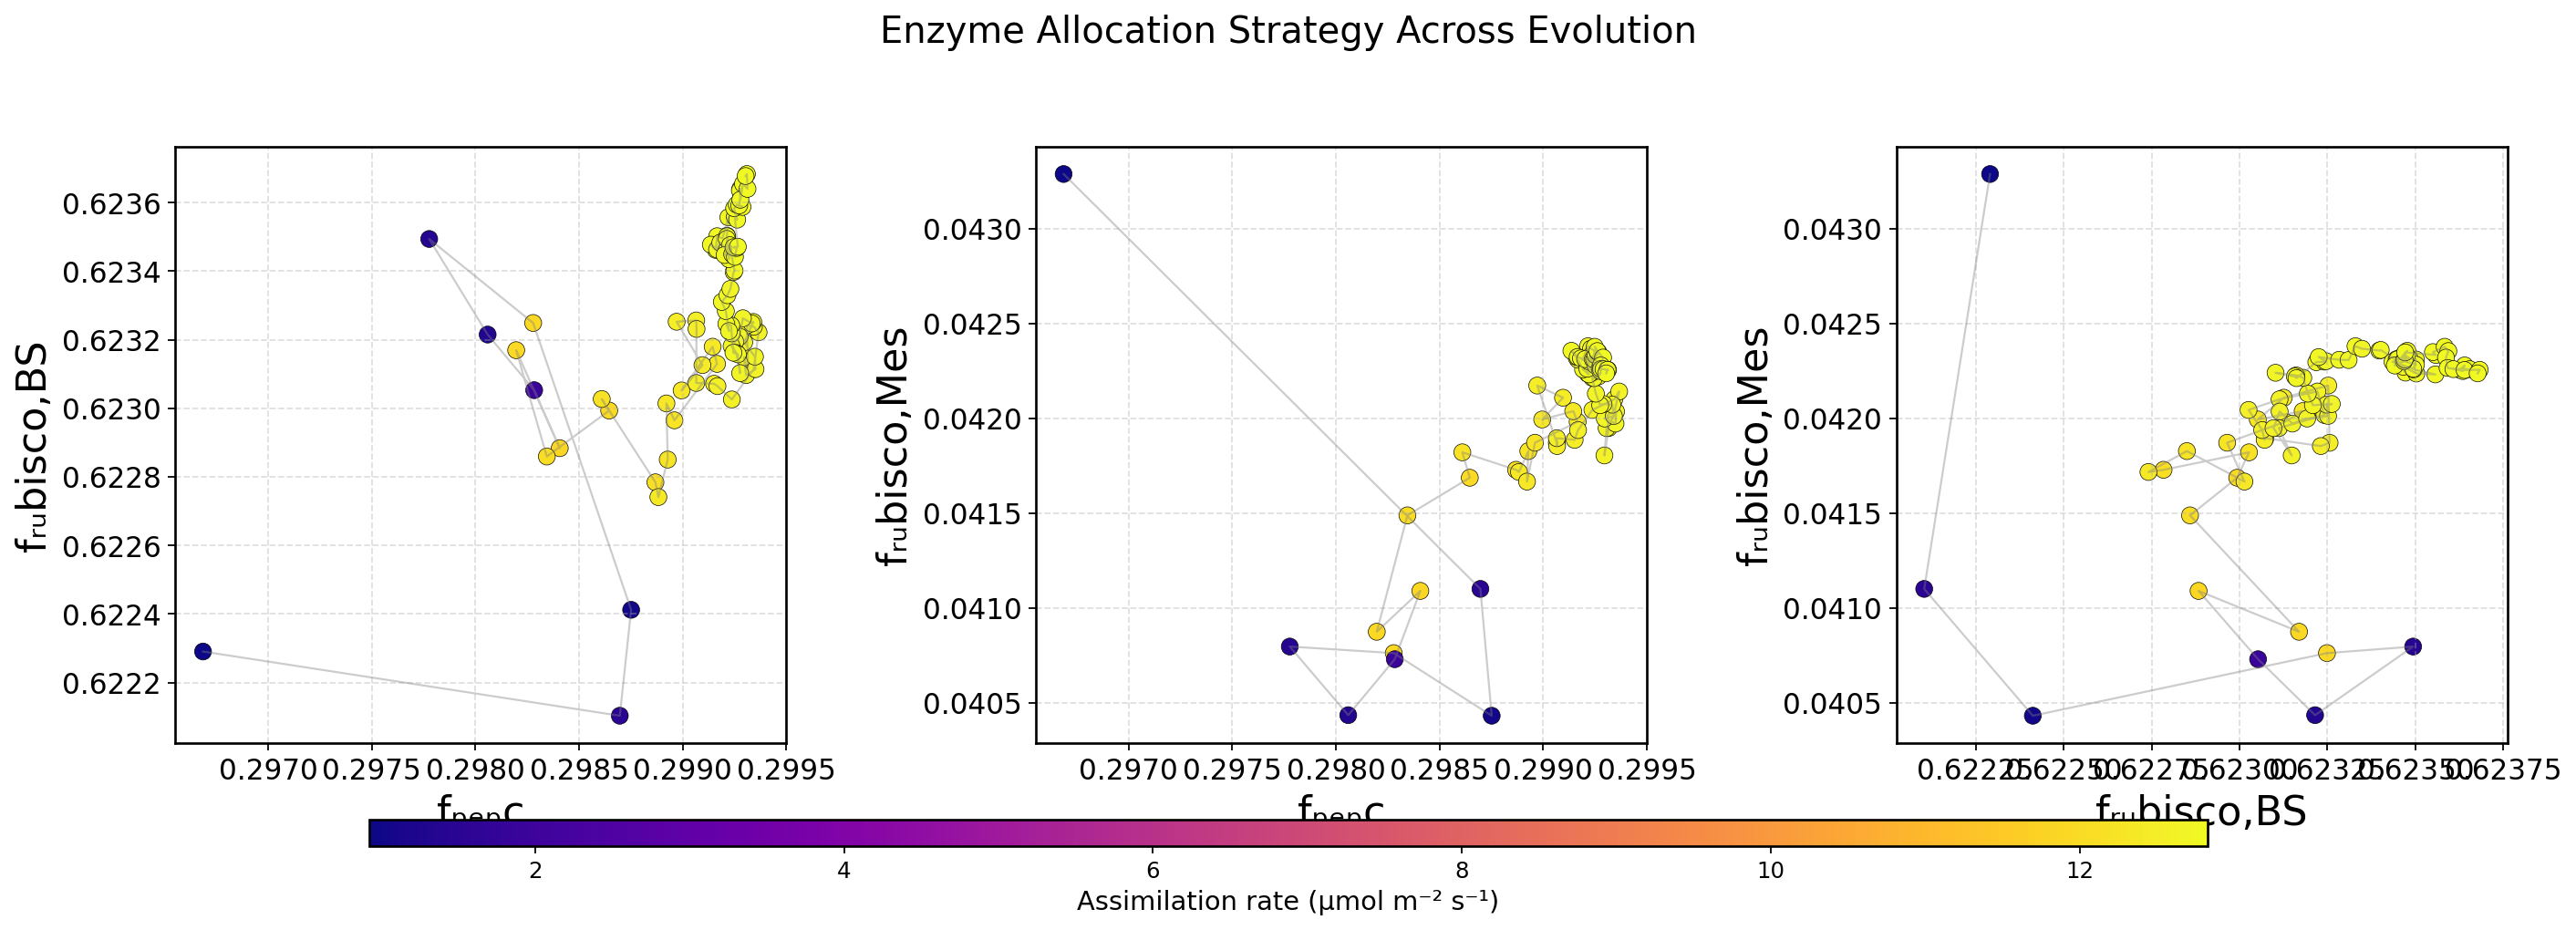

In [223]:


# Option 1 — Publication-ready 2D summary
plot_evolution_summary(
    loaded_history,
    save_path="plots/evolution/niger/evo_summary.png",
)




In [224]:
# Option 2 — Interactive 3D (for exploration)
import plotly.io as pio

pio.renderers.default = "notebook_connected"
# Or "iframe", "colab", "svg", "browser"

plot_3d_evolution_interactive(
    loaded_history,
    cmap_name="Viridis",
    save_html="plots/evolution/niger/evo_3d_interactive.html",
)

/home/foko.kuate/Final_yvonne /bachelor_project-main/photosynthesis_model/utils/evolution_plotting.py:1060: UserWarning:

This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.



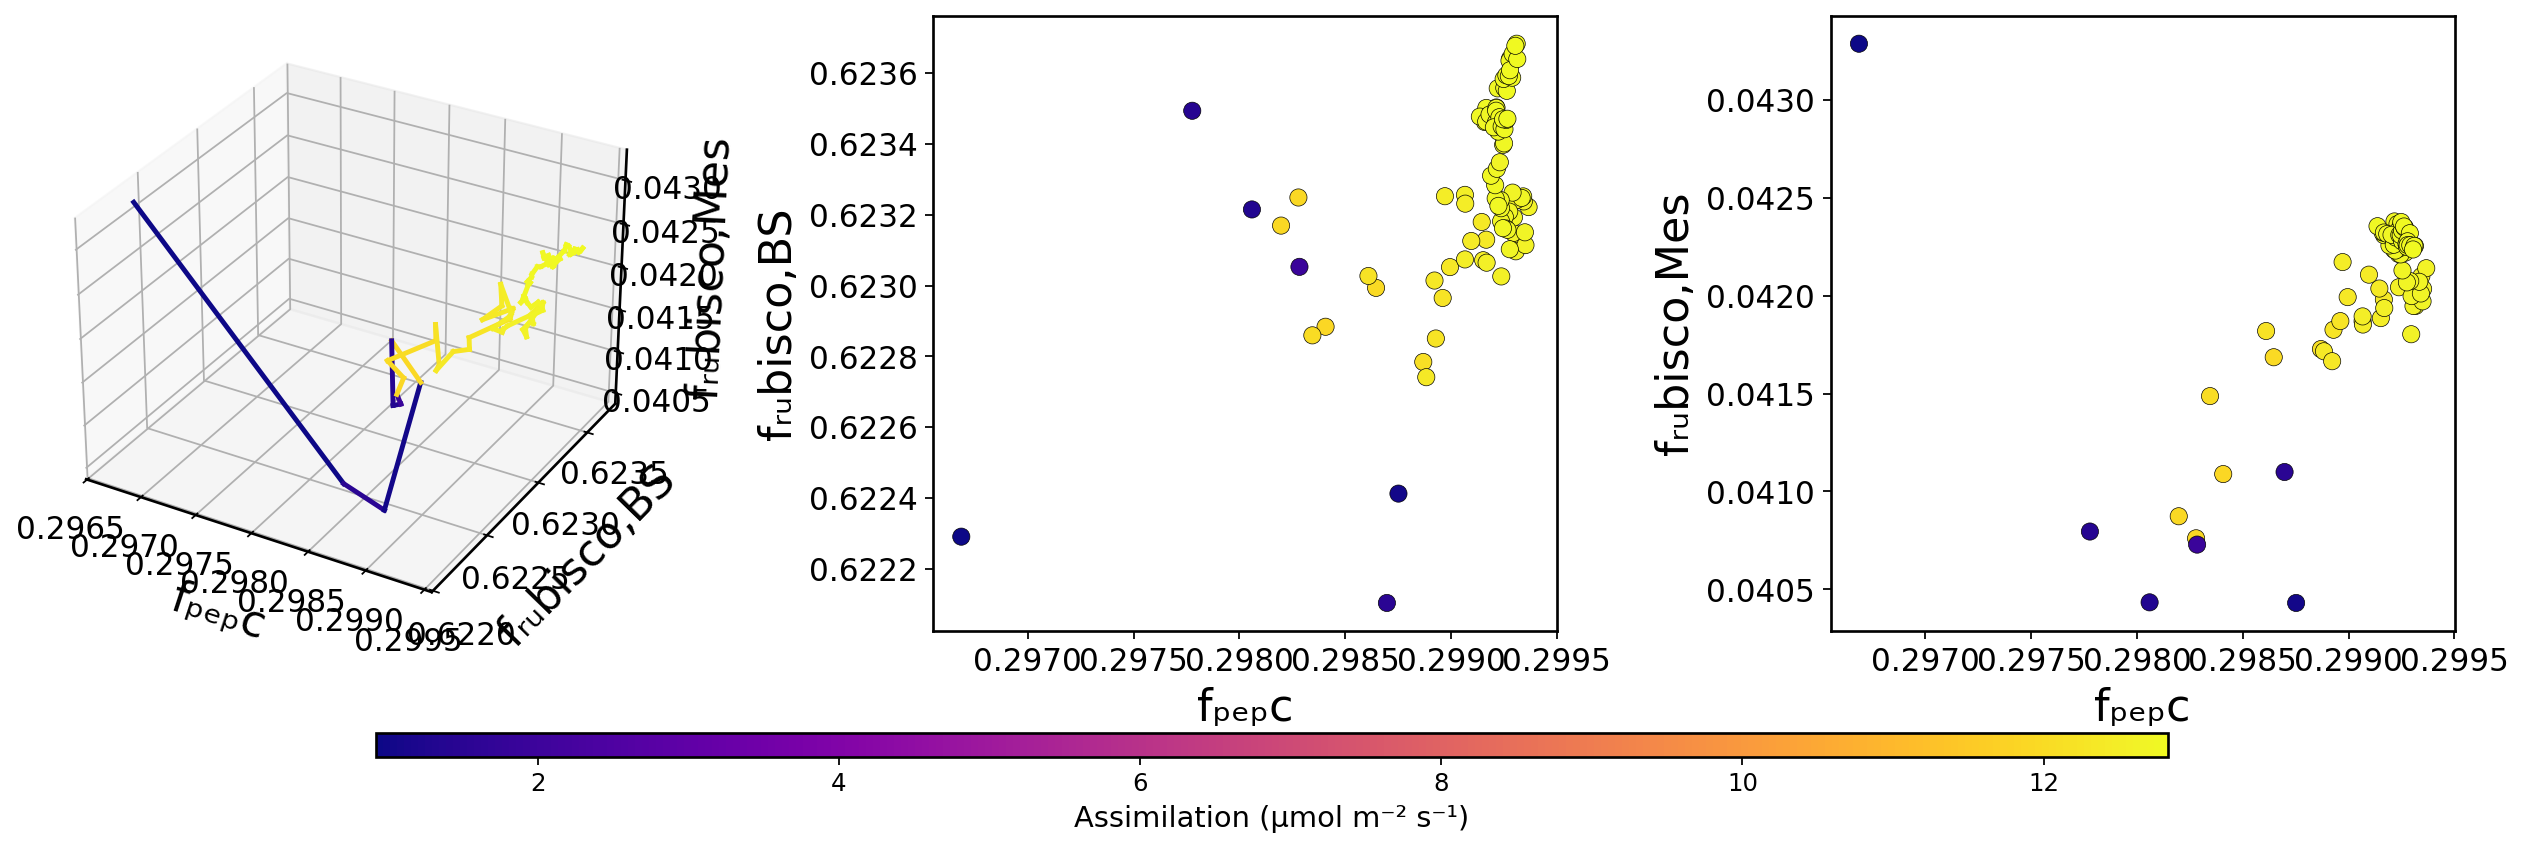

In [225]:
# Option 3 — Hybrid layout (for talks)
plot_hybrid_evolution_view(
    loaded_history,
    save_path="plots/evolution/niger/evo_hybrid_view.png",
)